# 04 · H4: Did Canada start selling new products to new markets?

**Hypothesis H4.** New non-US product × country export flows did not rise above the pre-tariff level.

**Frozen rule (M7).** A pair (HS6 product × non-US country) is new at a snapshot month when its exports were under CAD 100,000 in the 12 months that ended a year earlier, and over CAD 1 million in the latest 12 months at 3 consecutive month-ends. H4 is confirmed if the count at the latest month is within ±20% of the baseline mean, and rejected if it is above.

**Baselines.** Both baselines use the frozen snapshots: December 2023 (2023 vs 2022) and December 2024 (2024 vs 2023). The verdict is therefore the same for both.

All numbers come from `mart_extensive_margin`, `mart_extensive_margin_test`, `mart_extensive_margin_context` and `mart_extensive_margin_by_group`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

from src import analysis
from src.common import load_settings

pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_colwidth", 60)
con = analysis.connect()
start, end = analysis.tariff_window(con)
print(f"Tariff period (latest 12 months): {start} to {end}")

Tariff period (latest 12 months): Oct 2025 to Sep 2026


## Counts at each snapshot

In [2]:
pd.DataFrame(analysis.records(con, "select snapshot, role, variant, n_new_pairs from mart_extensive_margin order by variant, snapshot")).pivot(index=["snapshot", "role"], columns="variant", values="n_new_pairs")

,variant,ex_gold,ex_gold_ex_energy,total
snapshot,role,,,
2023-12-01,baseline,515,507,516
2024-12-01,baseline,495,484,495
2025-12-01,post_hoc,558,547,561
2026-09-01,tariff,599,592,605


Role `post_hoc` (the latest December) is context only; it is not part of the frozen rule.

## Verdict against the frozen band, both baselines

In [3]:
rows = []
for baseline, label in analysis.BASELINES.items():
    for r in analysis.h4(con, baseline):
        rows.append({
            "baseline": label, "variant": r["variant"], "snapshots": r["baseline_snapshots"],
            "baseline mean": r["baseline_mean"], "band low": r["low"], "band high": r["high"],
            "latest count": r["tariff_count"], "change vs mean (%)": 100 * r["change_vs_baseline"],
            "room to upper limit": r["high"] - r["tariff_count"], "H4 verdict": r["verdict"],
        })
h4_table = pd.DataFrame(rows)
h4_table

,baseline,variant,snapshots,baseline mean,band low,band high,latest count,change vs mean (%),room to upper limit,H4 verdict
0,2022–2024,total,"Dec 2023, Dec 2024",505.500,404.400,606.600,605,19.683,1.600,confirmed
1,2022–2024,ex_gold,"Dec 2023, Dec 2024",505.000,404.000,606.000,599,18.614,7.000,confirmed
2,2022–2024,ex_gold_ex_energy,"Dec 2023, Dec 2024",495.500,396.400,594.600,592,19.475,2.600,confirmed
3,2023–2024,total,"Dec 2023, Dec 2024",505.500,404.400,606.600,605,19.683,1.600,confirmed
4,2023–2024,ex_gold,"Dec 2023, Dec 2024",505.000,404.000,606.000,599,18.614,7.000,confirmed
5,2023–2024,ex_gold_ex_energy,"Dec 2023, Dec 2024",495.500,396.400,594.600,592,19.475,2.600,confirmed


In [4]:
for variant in h4_table["variant"].unique():
    sub = h4_table[h4_table["variant"] == variant]
    p, s = sub.iloc[0], sub.iloc[1]
    change = "same verdict" if p["H4 verdict"] == s["H4 verdict"] else "VERDICT CHANGES between baselines"
    print(f"{variant}: {p['latest count']} new pairs, {p['change vs mean (%)']:+.1f}% vs the 2022–2024 mean "
          f"({p['H4 verdict']}, {p['room to upper limit']:.1f} below the upper limit) and "
          f"{s['change vs mean (%)']:+.1f}% vs the 2023–2024 baseline ({s['H4 verdict']}); {change}.")

total: 605 new pairs, +19.7% vs the 2022–2024 mean (confirmed, 1.6 below the upper limit) and +19.7% vs the 2023–2024 baseline (confirmed); same verdict.
ex_gold: 599 new pairs, +18.6% vs the 2022–2024 mean (confirmed, 7.0 below the upper limit) and +18.6% vs the 2023–2024 baseline (confirmed); same verdict.
ex_gold_ex_energy: 592 new pairs, +19.5% vs the 2022–2024 mean (confirmed, 2.6 below the upper limit) and +19.5% vs the 2023–2024 baseline (confirmed); same verdict.


## Context only, not verdicts

*Exploratory, defined after seeing the result:* the latest count against the December 2024 snapshot alone. *Post hoc:* the count at the latest December, the same calendar month as the baseline snapshots.

In [5]:
pd.DataFrame(analysis.records(con, "select kind, description, variant, snapshot, n_new_pairs, reference, change_vs_reference from mart_extensive_margin_context order by kind, variant"))

,kind,description,variant,snapshot,n_new_pairs,reference,change_vs_reference
0,exploratory,Latest count vs the Dec 2024 snapshot alone (defined aft...,ex_gold,2026-09-01,599,495.000,0.210
1,exploratory,Latest count vs the Dec 2024 snapshot alone (defined aft...,ex_gold_ex_energy,2026-09-01,592,484.000,0.223
2,exploratory,Latest count vs the Dec 2024 snapshot alone (defined aft...,total,2026-09-01,605,495.000,0.222
3,post_hoc,Count at Dec 2025 (same calendar month as the baseline s...,ex_gold,2025-12-01,558,505.000,0.105
4,post_hoc,Count at Dec 2025 (same calendar month as the baseline s...,ex_gold_ex_energy,2025-12-01,547,495.500,0.104
5,post_hoc,Count at Dec 2025 (same calendar month as the baseline s...,total,2025-12-01,561,505.500,0.110


## Front-loading check

The latest snapshot looks back at a prior 12-month window that includes the front-loading months (November 2024 to February 2025). If exports were inflated then, fewer pairs look new, which pushes the test toward confirmation.

In [6]:
pd.DataFrame(analysis.records(con, "select * from mart_frontload_check"))

,variant,destination,year_before,frontload,change_pct
0,ex_gold_ex_energy,Non-US,"40,648,817,625.000","41,937,171,881.000",0.032
1,ex_gold_ex_energy,United States,"116,910,087,606.000","123,283,833,143.000",0.055
2,total,Non-US,"56,204,989,607.000","58,159,339,438.000",0.035
3,total,United States,"178,267,802,961.000","195,989,073,868.000",0.099


## Where the new pairs are

Top 5 destination countries and top 5 HS2 chapters at the latest snapshot (ties kept), next to the baseline mean for the same country or chapter.

In [7]:
cols = ["rank_in_snapshot", "code", "label", "n_new_pairs", "n_new_pairs_ex_gold_ex_energy", "n_gold", "baseline_mean", "change_vs_baseline_mean"]
display(pd.DataFrame(analysis.h4_top(con, "country"))[cols])
display(pd.DataFrame(analysis.h4_top(con, "hs2"))[cols])
print("Largest rises against each group's own baseline mean:")
display(pd.DataFrame(analysis.h4_risers(con, "country", 5))[cols])
display(pd.DataFrame(analysis.h4_risers(con, "hs2", 5))[cols])

,rank_in_snapshot,code,label,n_new_pairs,n_new_pairs_ex_gold_ex_energy,n_gold,baseline_mean,change_vs_baseline_mean
0,1,CN,China,31,31,0,21.500,9.500
1,2,NL,Netherlands,19,18,1,12.500,6.500
2,2,GB,United Kingdom,19,18,1,6.500,12.500
3,4,ES,Spain,18,16,1,7.000,11.000
4,5,BR,Brazil,16,16,0,11.000,5.000
5,5,DE,Germany,16,16,0,12.000,4.000
6,5,IN,India,16,16,0,8.500,7.500
7,5,KR,"Korea, South",16,15,1,11.500,4.500
8,5,MX,Mexico,16,16,0,12.500,3.500


,rank_in_snapshot,code,label,n_new_pairs,n_new_pairs_ex_gold_ex_energy,n_gold,baseline_mean,change_vs_baseline_mean
0,1,84,"Nuclear reactors, boilers, machinery and mechanical appl...",176,176,0,158.500,17.500
1,2,85,"Elec mchy,equip & pts;snd record & repro,tv image & snd ...",46,46,0,37.000,9.000
2,3,90,Inst & app for optical/photo/cine/meas/chk/precision/med...,39,39,0,23.000,16.000
3,4,87,"Vehicles, o/t railway or tramway rolling-stock,and parts...",28,28,0,14.000,14.000
4,5,88,"Aircraft, spacecraft, and parts thereof",26,26,0,33.500,-7.500
5,5,71,"Nat/cult pearls,prec/semi-prec stones,prec met,clad,art ...",26,20,6,5.500,20.500


Largest rises against each group's own baseline mean:


,rank_in_snapshot,code,label,n_new_pairs,n_new_pairs_ex_gold_ex_energy,n_gold,baseline_mean,change_vs_baseline_mean
0,2,GB,United Kingdom,19,18,1,6.500,12.500
1,4,ES,Spain,18,16,1,7.000,11.000
2,1,CN,China,31,31,0,21.500,9.500
3,15,NG,Nigeria,11,11,0,2.000,9.000
4,5,IN,India,16,16,0,8.500,7.500


,rank_in_snapshot,code,label,n_new_pairs,n_new_pairs_ex_gold_ex_energy,n_gold,baseline_mean,change_vs_baseline_mean
0,5,71,"Nat/cult pearls,prec/semi-prec stones,prec met,clad,art ...",26,20,6,5.500,20.500
1,1,84,"Nuclear reactors, boilers, machinery and mechanical appl...",176,176,0,158.500,17.500
2,3,90,Inst & app for optical/photo/cine/meas/chk/precision/med...,39,39,0,23.000,16.000
3,4,87,"Vehicles, o/t railway or tramway rolling-stock,and parts...",28,28,0,14.000,14.000
4,2,85,"Elec mchy,equip & pts;snd record & repro,tv image & snd ...",46,46,0,37.000,9.000


## Charts

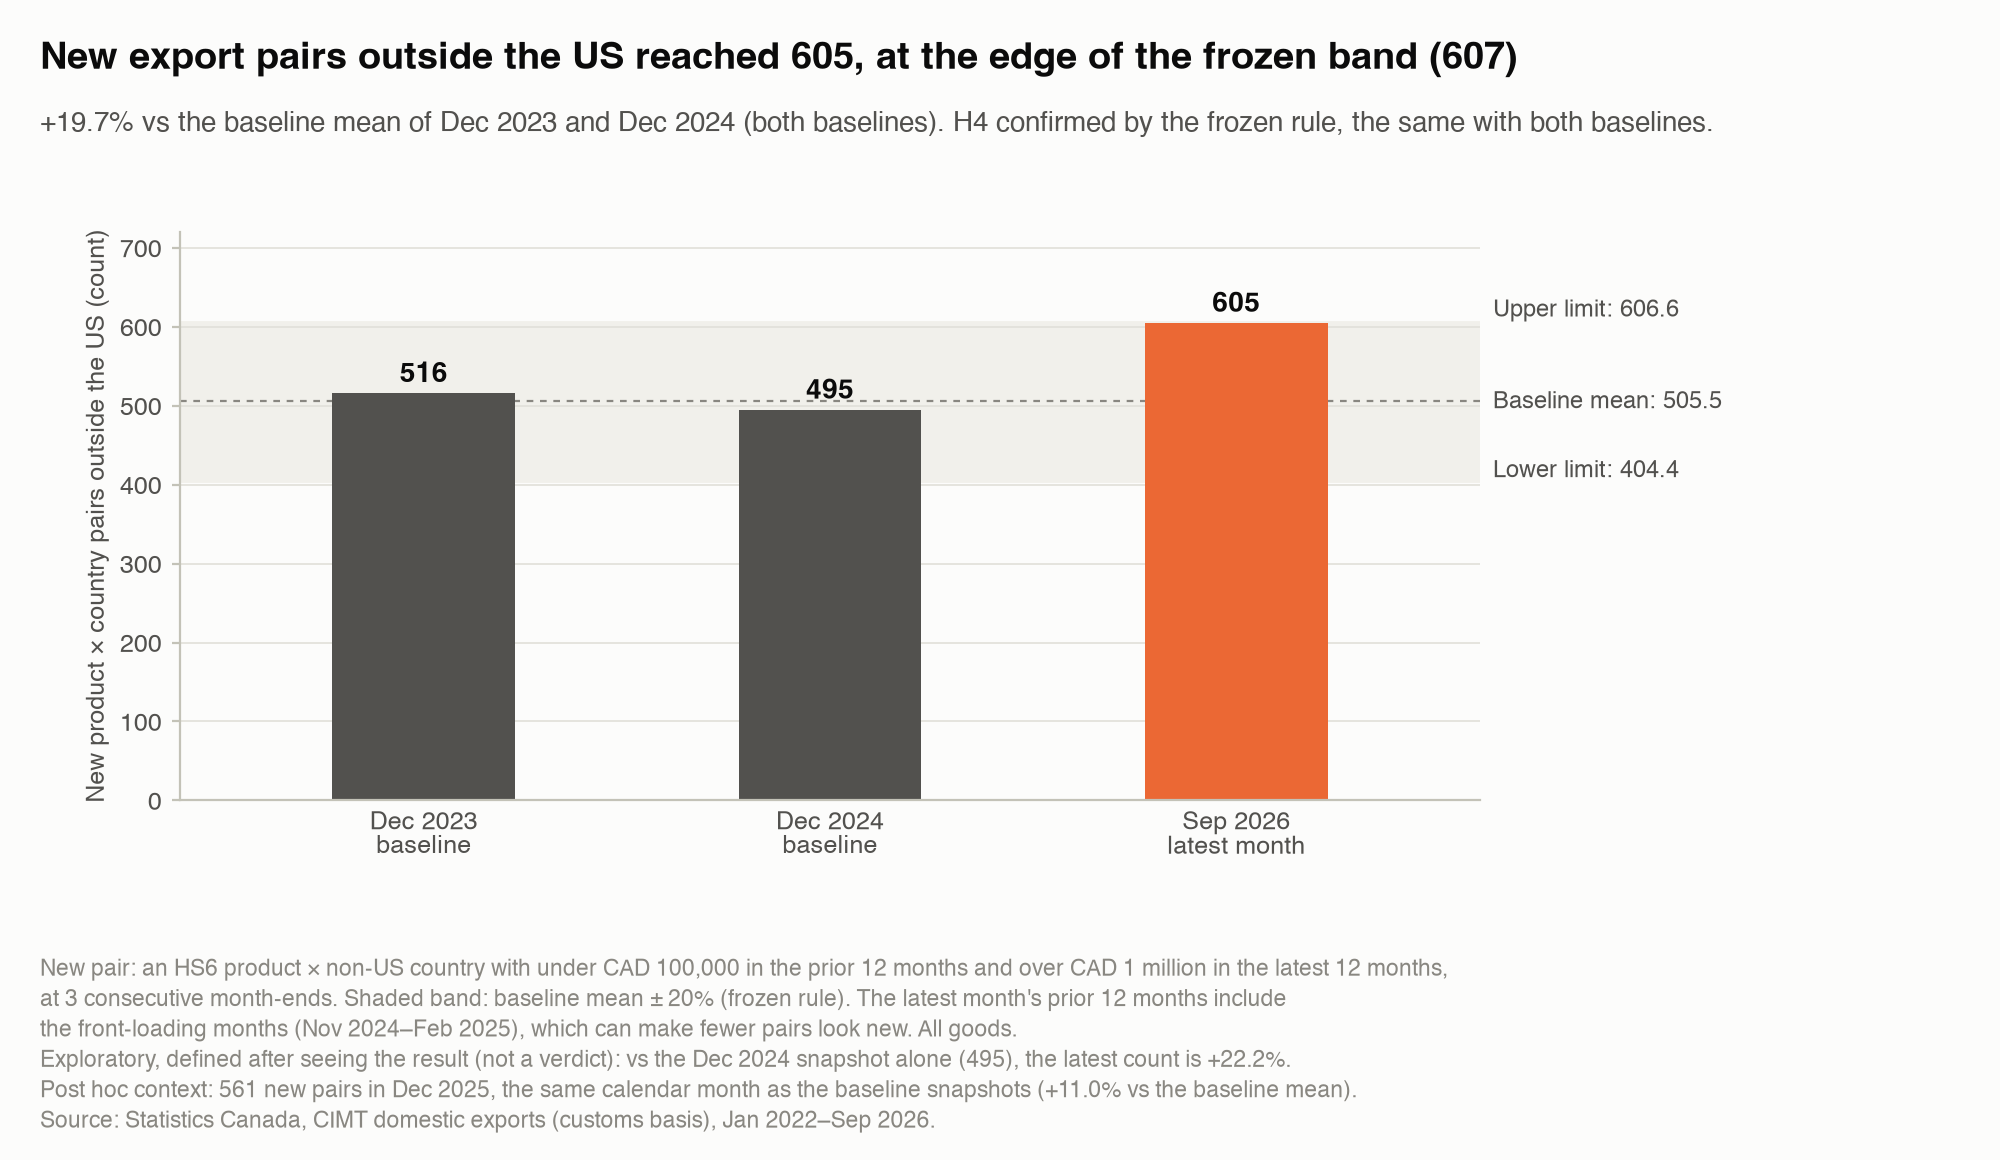

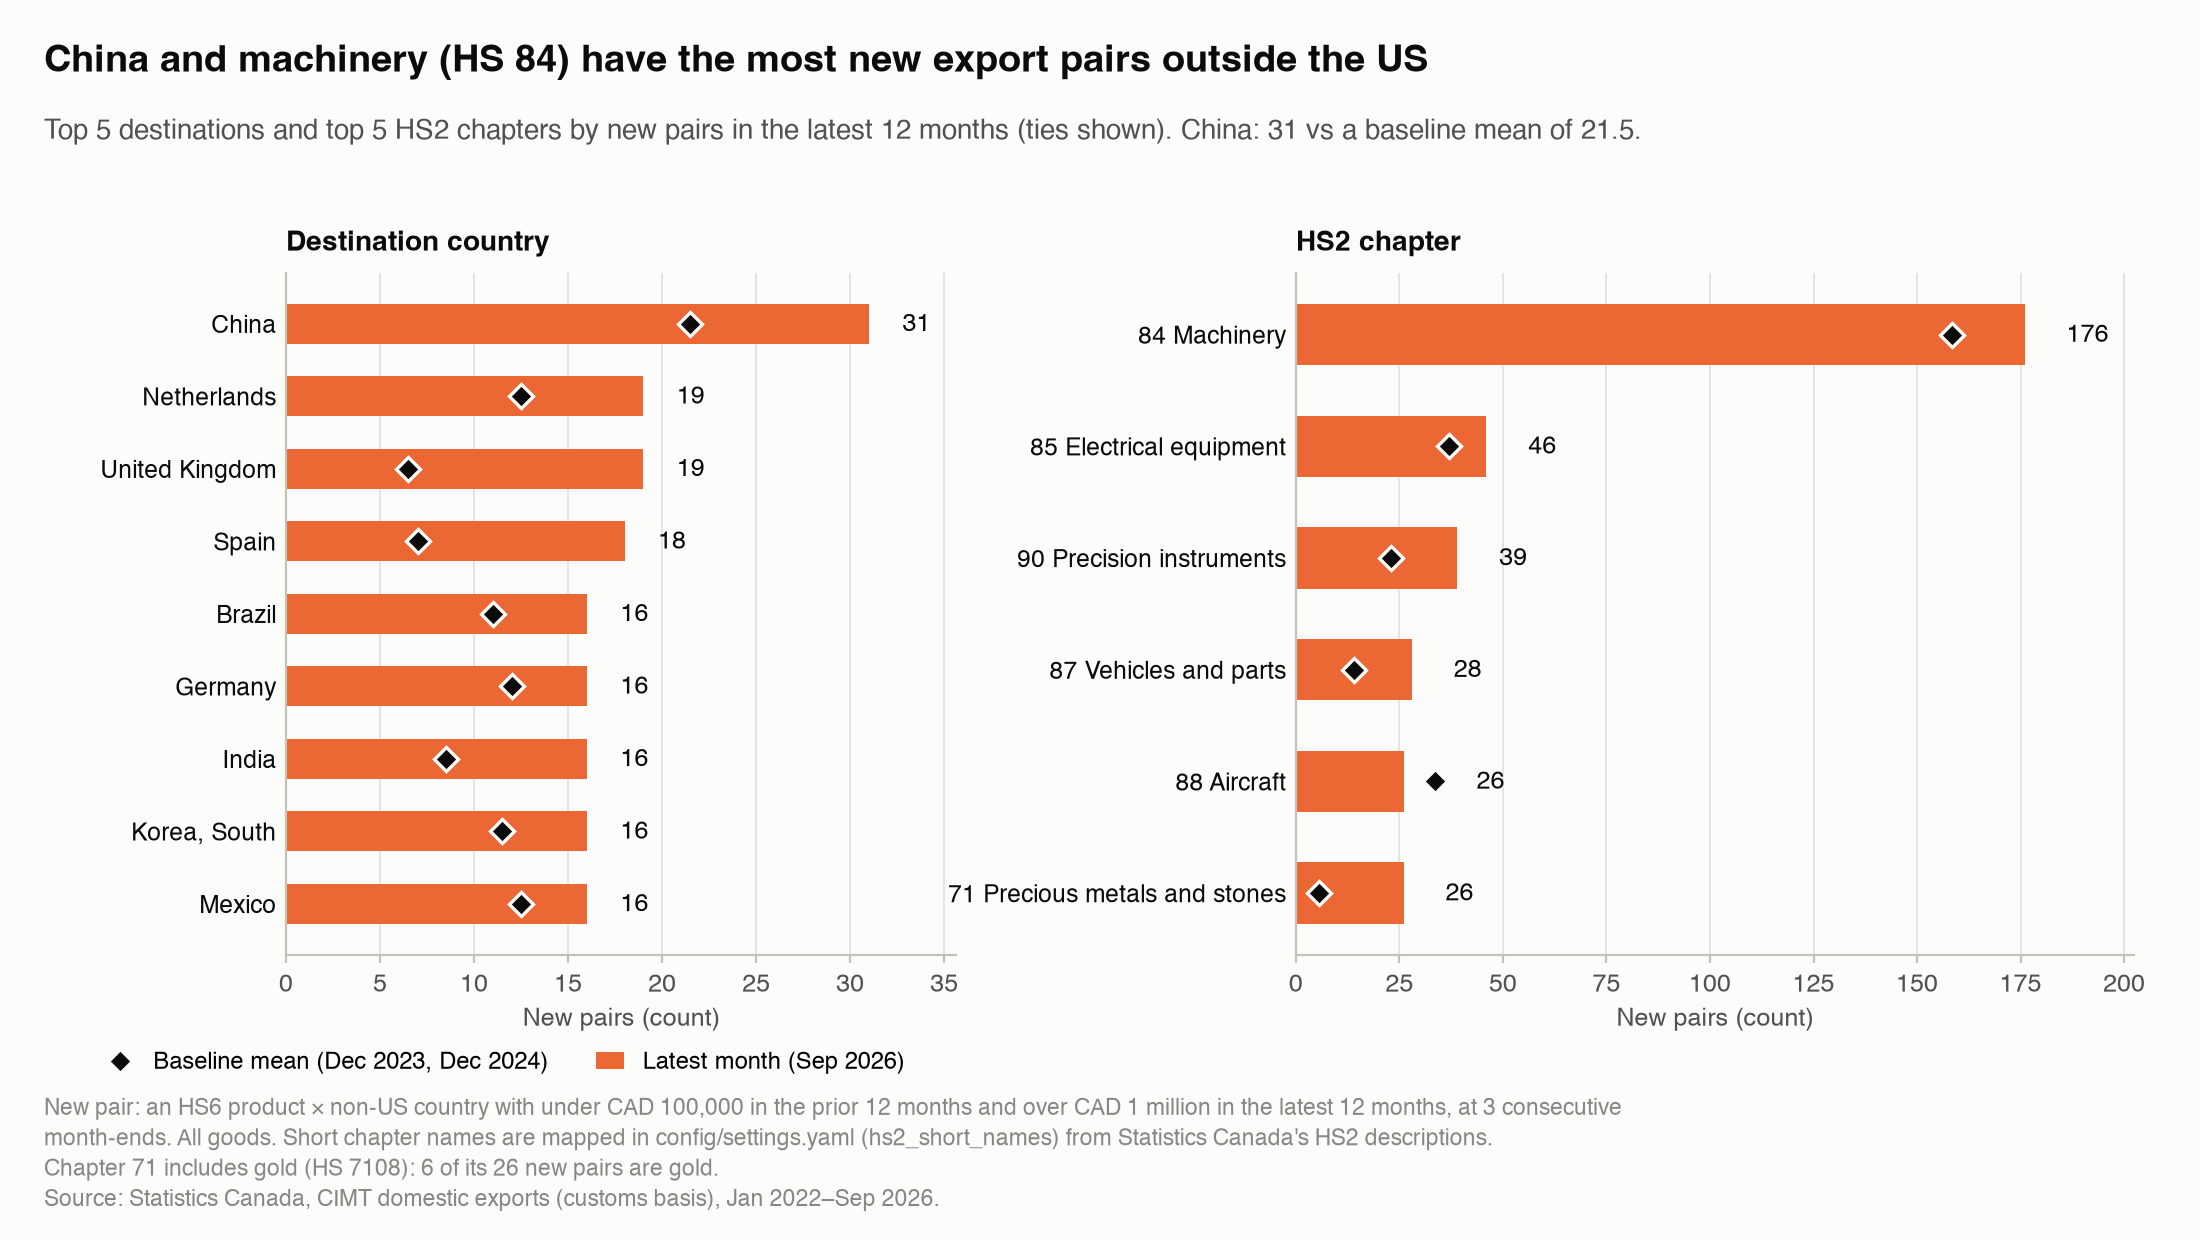

In [8]:
display(Image(filename=str(ROOT / "figures" / "h4_new_pairs.png"), width=950))
display(Image(filename=str(ROOT / "figures" / "h4_where_new_pairs.png"), width=1000))

## Notes

- The count is at the edge of the band. The front-loading bias pushes the count down, so this result cannot rule out a moderate rise in new export pairs.
- A pair counts as new only after three month-ends above CAD 1 million, so flows that started late in the period are not yet counted.
- This is a description of the data. It does not show that tariffs caused the changes.